In [1]:
import pandas as pd
from google.colab import files
from sklearn.model_selection import train_test_split, StratifiedKFold

uploaded = files.upload()

df = pd.read_excel("final_labeled_clean_v3.xlsx")

df.columns = df.columns.str.strip()

df = df[["Clean Text", "Final Label"]]
df = df.rename(columns={
    "Clean Text": "text",
    "Final Label": "label"
})

Saving final_labeled_clean_v3.xlsx to final_labeled_clean_v3.xlsx


In [2]:
X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=18
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=18
)

print("Train:", len(X_train))
print("Test:", len(X_test))

print("\nPhân bố nhãn Train:")
print(y_train.value_counts())


Train: 1669
Test: 418

Phân bố nhãn Train:
label
Positive    1024
Neutral      350
Negative     295
Name: count, dtype: int64


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score

model_tfidf = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2)),
    LinearSVC(
        C=1.0,
        random_state=18
    )
)

scores_tfidf = cross_val_score(
    model_tfidf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("Macro F1 từng fold:", scores_tfidf)
print("Macro F1 trung bình:", scores_tfidf.mean())

Macro F1 từng fold: [0.58592375 0.53029988 0.59845732 0.52982129 0.60459786]
Macro F1 trung bình: 0.5698200215130719


=== TF-IDF + Linear SVM (OvR) ===
              precision    recall  f1-score   support

    Negative     0.5954    0.3492    0.4402       295
     Neutral     0.6121    0.3743    0.4645       350
    Positive     0.7262    0.9092    0.8075      1024

    accuracy                         0.6980      1669
   macro avg     0.6446    0.5442    0.5707      1669
weighted avg     0.6792    0.6980    0.6706      1669



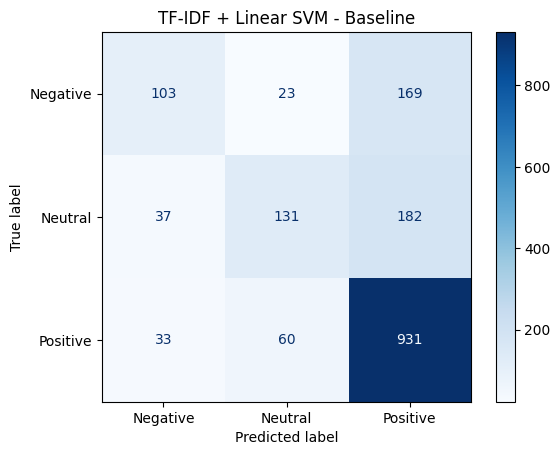

In [5]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred_tfidf = cross_val_predict(
    model_tfidf,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

print("=== TF-IDF + Linear SVM (OvR) ===")
print(classification_report(
    y_train,
    y_pred_tfidf,
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_tfidf,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF + Linear SVM - Baseline")
plt.show()


In [6]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    "linearsvc__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "linearsvc__class_weight": [None, "balanced"]
}

grid_ovr = GridSearchCV(
    estimator=model_tfidf,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    refit=True
)

grid_ovr.fit(X_train, y_train)

print("Best Parameters:", grid_ovr.best_params_)
print("Best Macro F1:", grid_ovr.best_score_)


Best Parameters: {'linearsvc__C': 1, 'linearsvc__class_weight': 'balanced'}
Best Macro F1: 0.6009449142015433


In [7]:
#tối ưu hoá tfidf
from sklearn.model_selection import GridSearchCV

param_grid_tfidf = {
    "tfidfvectorizer__ngram_range": [(1,1), (1,2), (1,3)],
    "tfidfvectorizer__min_df": [1, 2, 3],
    "tfidfvectorizer__sublinear_tf": [False, True]
}

grid_tfidf = GridSearchCV(
    estimator=grid_ovr.best_estimator_,
    param_grid=param_grid_tfidf,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    refit=True
)

grid_tfidf.fit(X_train, y_train)

print("Best Parameters:", grid_tfidf.best_params_)
print("Best Macro F1:", grid_tfidf.best_score_)


Best Parameters: {'tfidfvectorizer__min_df': 1, 'tfidfvectorizer__ngram_range': (1, 2), 'tfidfvectorizer__sublinear_tf': False}
Best Macro F1: 0.6009449142015433


=== TF-IDF + SVM (OvR) Optimized ===
              precision    recall  f1-score   support

    Negative     0.5670    0.4305    0.4894       295
     Neutral     0.5833    0.4400    0.5016       350
    Positive     0.7595    0.8760    0.8136      1024

    accuracy                         0.7058      1669
   macro avg     0.6366    0.5822    0.6015      1669
weighted avg     0.6885    0.7058    0.6909      1669



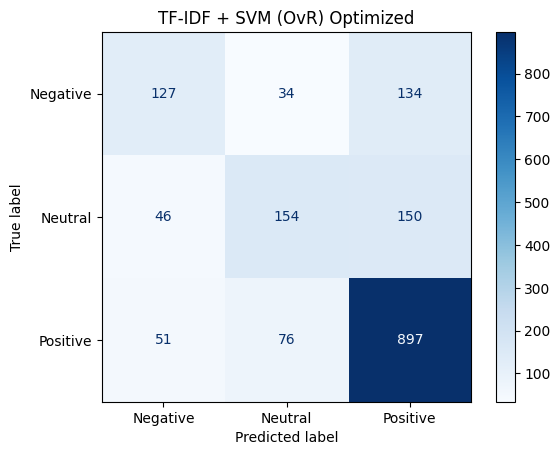

In [8]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Lấy cấu hình OvR tốt nhất
best_ovr = grid_tfidf.best_estimator_

# 2. Dự đoán ngoài fold trên Train
y_pred_ovr = cross_val_predict(
    best_ovr,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

# 3. Đánh giá từng nhãn
print("=== TF-IDF + SVM (OvR) Optimized ===")
print(classification_report(
    y_train,
    y_pred_ovr,
    digits=4
))

# 4. Vẽ ma trận nhầm lẫn
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_ovr,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF + SVM (OvR) Optimized")
plt.show()


TF-IDF + Linear SVM (OvO)


In [10]:

from sklearn.multiclass import OneVsOneClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_score

model_ovo = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2)),
    OneVsOneClassifier(
        LinearSVC(
            C=1.0,
            class_weight=None,
            max_iter=10000,
            random_state=18
        )
    )
)

scores_ovo = cross_val_score(
    model_ovo,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2
)

print("Macro F1 từng fold:", scores_ovo)
print("Macro F1 trung bình:", scores_ovo.mean())


Macro F1 từng fold: [0.59326844 0.52855399 0.59313503 0.53969828 0.55747649]
Macro F1 trung bình: 0.5624264481854448


In [11]:
from sklearn.model_selection import GridSearchCV

param_grid_ovo = {
    "onevsoneclassifier__estimator__C": [
        0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10
    ],
    "onevsoneclassifier__estimator__class_weight": [
        None, "balanced"
    ]
}

grid_ovo = GridSearchCV(
    estimator=model_ovo,
    param_grid=param_grid_ovo,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    refit=True
)


grid_ovo.fit(X_train, y_train)

print("Best Parameters:", grid_ovo.best_params_)
print("Best Macro F1:", grid_ovo.best_score_)


Best Parameters: {'onevsoneclassifier__estimator__C': 0.3, 'onevsoneclassifier__estimator__class_weight': 'balanced'}
Best Macro F1: 0.612843950686855


In [12]:
from sklearn.model_selection import GridSearchCV

param_grid_tfidf_ovo = {
    "tfidfvectorizer__ngram_range": [(1,1), (1,2), (1,3)],
    "tfidfvectorizer__min_df": [1, 2, 3],
    "tfidfvectorizer__sublinear_tf": [False, True]
}

grid_ovo_tfidf = GridSearchCV(
    estimator=grid_ovo.best_estimator_,
    param_grid=param_grid_tfidf_ovo,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    refit=True
)

grid_ovo_tfidf.fit(X_train, y_train)

print("Best Parameters:", grid_ovo_tfidf.best_params_)
print("Best Macro F1:", grid_ovo_tfidf.best_score_)


Best Parameters: {'tfidfvectorizer__min_df': 1, 'tfidfvectorizer__ngram_range': (1, 2), 'tfidfvectorizer__sublinear_tf': False}
Best Macro F1: 0.612843950686855


**TF-IDF + SVM RBF**

In [14]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_score

model_rbf = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2)),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        random_state=18
    )
)

scores_rbf = cross_val_score(
    model_rbf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2
)

print("Macro F1 từng fold:", scores_rbf)
print("Macro F1 trung bình:", scores_rbf.mean())


Macro F1 từng fold: [0.56054889 0.53354119 0.60232093 0.51002174 0.52879979]
Macro F1 trung bình: 0.5470465065625298


In [15]:
from sklearn.model_selection import GridSearchCV

param_grid_rbf = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.01, 0.1, 1, "scale"]
}

grid_rbf = GridSearchCV(
    estimator=model_rbf,
    param_grid=param_grid_rbf,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    refit=True
)

grid_rbf.fit(X_train, y_train)

print("Best Parameters:", grid_rbf.best_params_)
print("Best Macro F1:", grid_rbf.best_score_)


Best Parameters: {'svc__C': 100, 'svc__gamma': 0.01}
Best Macro F1: 0.5918372795313902


In [16]:

from sklearn.model_selection import GridSearchCV

# Tinh chỉnh quanh cấu hình tốt nhất
param_grid_rbf_fine = {
    "svc__C": [30, 100, 300],
    "svc__gamma": [0.003, 0.01, 0.03]
}

grid_rbf_fine = GridSearchCV(
    estimator=grid_rbf.best_estimator_,
    param_grid=param_grid_rbf_fine,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    refit=True
)

grid_rbf_fine.fit(X_train, y_train)

print("Best Parameters:", grid_rbf_fine.best_params_)
print("Best Macro F1:", grid_rbf_fine.best_score_)


Best Parameters: {'svc__C': 100, 'svc__gamma': 0.003}
Best Macro F1: 0.612078582066091


=== Best TF-IDF + SVM (OvO) ===
              precision    recall  f1-score   support

    Negative     0.5033    0.5186    0.5109       295
     Neutral     0.5686    0.4971    0.5305       350
    Positive     0.7856    0.8125    0.7988      1024

    accuracy                         0.6944      1669
   macro avg     0.6192    0.6094    0.6134      1669
weighted avg     0.6902    0.6944    0.6917      1669



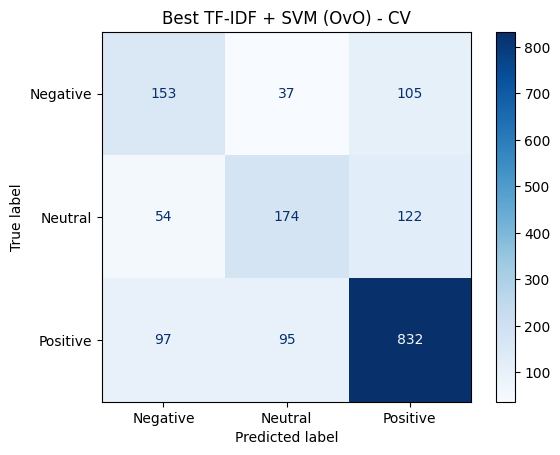

In [17]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_tfidf = grid_ovo_tfidf.best_estimator_

y_pred_best = cross_val_predict(
    best_tfidf,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

print("=== Best TF-IDF + SVM (OvO) ===")
print(classification_report(
    y_train,
    y_pred_best,
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_best,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Best TF-IDF + SVM (OvO) - CV")
plt.show()


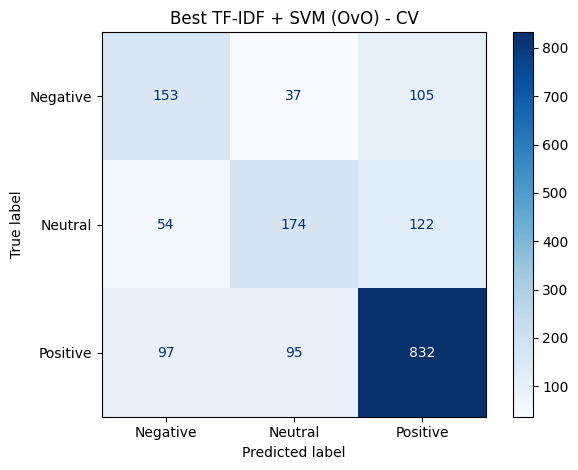

Best CV Macro F1: 0.612843950686855
Đã lưu 3 file thành công.


In [18]:

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 1. Lưu mô hình đã huấn luyện
joblib.dump(best_tfidf, "best_tfidf_svm.joblib")

# 2. Lưu Precision, Recall, F1-score, Support
report = classification_report(
    y_train,
    y_pred_best,
    output_dict=True
)

metrics = pd.DataFrame(report).T
metrics.to_csv("best_tfidf_metrics.csv")

# 3. Vẽ và lưu Confusion Matrix
labels = ["Negative", "Neutral", "Positive"]

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_best,
    labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("Best TF-IDF + SVM (OvO) - CV")
plt.tight_layout()
plt.savefig("best_tfidf_confusion_matrix.png", dpi=300)
plt.show()

print("Best CV Macro F1:", grid_ovo_tfidf.best_score_)
print("Đã lưu 3 file thành công.")
